# 04 · Clustering States into Thermal-Demand Zones
**Problem:** one national target, 33 states of weather.
* 33 states x ~25 weather columns = ~800 features for ~1,700 training days, and the trees would chase noise.
* A single national average would cancel a Rajasthan heatwave against a rainy Kerala.

**Solution:** group states that share a *climate* **and** a *demand behaviour* into zones, and give the model one set of
demand-weighted weather signals per zone.

Why not just use the official grid regions? They are electrical and administrative, not climatic. NR mixes desert Rajasthan with snowy,
winter-peaking Himachal. We compare our zones with them only as a sanity check.

In [1]:
# --- common setup ------------------------------------------------------------
# The project code lives in src/heatwave_peak (installed with `pip install -e .`).
# If it is not installed, fall back to adding src/ to the import path.
import sys, warnings
from pathlib import Path
try:
    import heatwave_peak
except ImportError:
    sys.path.insert(0, str(Path.cwd().parent / "src"))
    import heatwave_peak
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from heatwave_peak import config as C

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    """Save the current figure to reports/figures/<name>.png."""
    plt.savefig(C.FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

In [2]:
from heatwave_peak import clustering as CL
sw = pd.read_parquet(C.INTERIM_DIR / "state_daily_weather_1991_2025.parquet")
sd = pd.read_parquet(C.INTERIM_DIR / "state_daily_demand.parquet")
w = pd.read_csv(C.PROCESSED_DIR / "state_demand_weights.csv", index_col=0)["demand_weight"]
sig = CL.build_state_signatures(sw, sd)
sig.round(2)

,tmax_annual_mean,tmax_seasonal_amplitude,tmax_premonsoon_AMJ,diurnal_range,dmt_p95,heat_days_per_year,hot_month_sin,hot_month_cos,rh_mean,dewpoint_premonsoon,heat_index_AMJ,monsoon_rain_share,summer_winter_ratio,monsoon_dip,peak_demand_month_sin,peak_demand_month_cos,heat_sensitivity_pct_per_C,lat,lon,grid_region
Andhra Pradesh,33.23,9.10,37.14,10.73,32.83,17.27,0.87,-0.50,71.70,22.01,40.66,0.64,1.05,0.89,0.87,0.50,2.05,16.51,80.65,SR
Arunachal Pradesh,29.27,9.15,30.69,10.37,29.76,16.33,-0.50,-0.87,79.06,21.22,31.41,0.50,0.95,1.02,0.00,1.00,0.47,27.08,93.61,NER
Assam,28.55,9.17,30.19,10.18,28.84,14.73,-0.50,-0.87,80.08,21.94,34.11,0.68,1.16,1.18,-0.50,-0.87,3.20,26.14,91.74,NER
Bihar,31.10,14.56,36.31,11.65,31.71,16.90,0.87,-0.50,70.44,19.60,39.51,0.83,1.22,1.08,-0.50,-0.87,2.45,25.59,85.14,ER
Chandigarh,28.91,18.98,35.65,12.81,31.26,17.00,0.87,-0.50,62.40,13.31,35.05,0.67,1.10,1.19,0.00,-1.00,3.01,30.73,76.78,NR
Chhattisgarh,32.34,13.65,38.44,12.44,33.77,17.47,0.87,-0.50,63.96,17.21,39.44,0.88,1.04,0.99,1.00,0.00,0.99,21.25,81.63,WR
Delhi,31.66,20.37,39.00,13.20,34.52,16.90,0.87,-0.50,62.99,14.41,37.43,0.72,1.23,1.14,0.50,-0.87,3.26,28.61,77.21,NR
Goa,31.49,6.04,33.01,9.82,29.89,15.90,1.00,0.00,77.97,24.41,36.81,0.87,1.05,0.92,1.00,0.00,1.46,15.50,73.83,WR
Gujarat,33.05,10.33,37.16,12.19,32.47,17.83,0.87,-0.50,56.05,16.92,40.17,0.93,1.05,0.86,1.00,0.00,2.43,23.02,72.57,WR
Haryana,31.12,20.02,38.24,13.41,33.78,17.57,0.87,-0.50,63.08,14.31,37.43,0.73,1.20,1.20,-0.50,-0.87,2.37,28.89,76.61,NR


### Reading the signature: three real-life examples
* **Delhi**: heat sensitivity ~ **+3.3 % demand per +1 C**, summer/winter ratio 1.23. A typical AC-driven city.
* **Rajasthan / MP / Telangana**: summer/winter ratio **< 1**. Their peak comes in *winter*, from rabi-season irrigation
  pumps, so a heatwave raises their demand less than you might expect.
* **Himachal / J&K / Meghalaya / Sikkim**: *negative* heat sensitivity (winter heating peak). Heat lowers their demand.

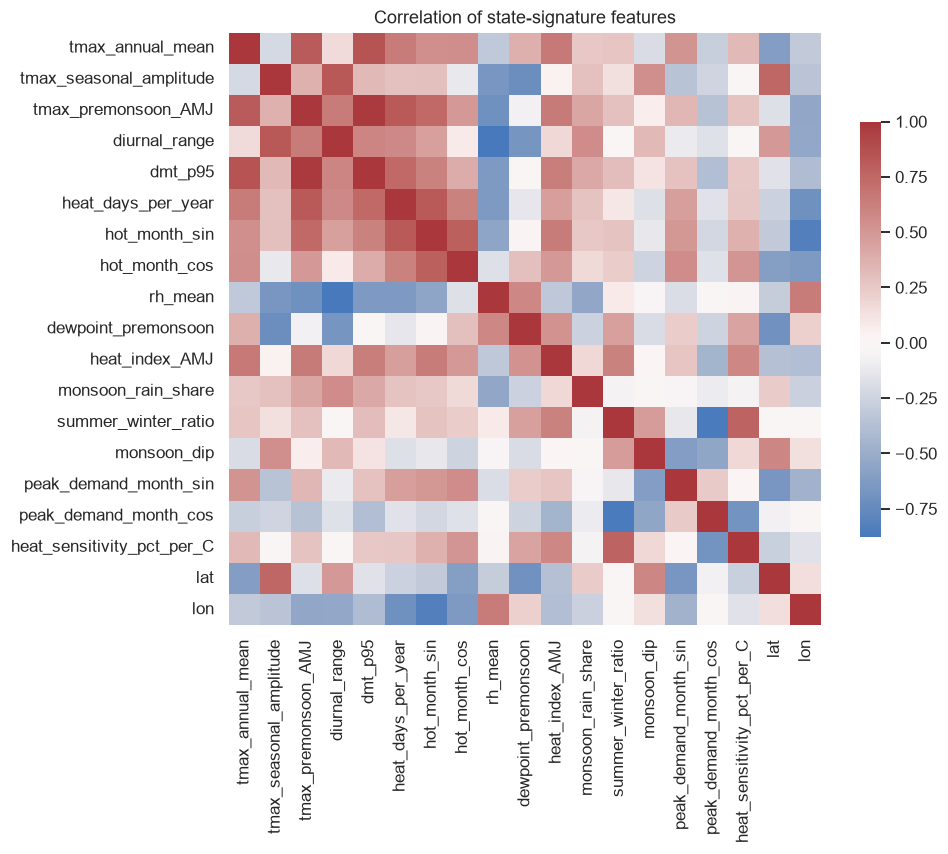

In [3]:
plt.figure(figsize=(9, 7))
num = sig.drop(columns=["grid_region"]).astype(float)
sns.heatmap(num.corr(), cmap="vlag", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Correlation of state-signature features"); savefig("04_signature_correlation"); plt.show()

## 1. Model selection: 4 algorithms x K = 3..8
* **k-means**: spherical clusters, the default baseline
* **Ward**: agglomerative clustering that minimises within-cluster variance; deterministic, good for small n (33 states)
* **Ward + spatial connectivity**: a state may only merge with its 4 nearest geographic neighbours, so zones are **contiguous**, like real weather systems (heatwaves are synoptic-scale, 500-1500 km)
* **GMM**: Gaussian mixture, soft probabilistic clusters

Scores: silhouette (higher is better), Calinski-Harabasz (higher is better), Davies-Bouldin (lower is better). The winner has the best **mean rank** over the three,
because each index has a known bias on its own (silhouette favours small K, CH favours large K).
Solutions with a single-state "zone" are rejected.

In [4]:
X, cols = CL.scale_signatures(sig)
scores = CL.compare_clusterings(X, sig)
best = CL.select_clustering(scores)
show = scores.drop(columns="labels")
display(show.pivot(index="k", columns="algorithm", values="silhouette").round(3))
print("WINNER:", best["algorithm"], "K =", best["k"], "| silhouette %.3f | CH %.1f | DB %.3f | ARI vs grid %.2f" %
      (best.silhouette, best.calinski_harabasz, best.davies_bouldin, best.ari_vs_grid))

algorithm,gmm,kmeans,ward,ward_spatial
k,,,,
3,0.297,0.296,0.265,0.243
4,0.310,0.316,0.276,0.244
5,0.333,0.345,0.306,0.307
6,0.344,0.353,0.353,0.353
7,0.336,0.361,0.361,0.361
8,0.319,0.361,0.361,0.361


WINNER: ward_spatial K = 8 | silhouette 0.361 | CH 16.4 | DB 0.816 | ARI vs grid 0.42


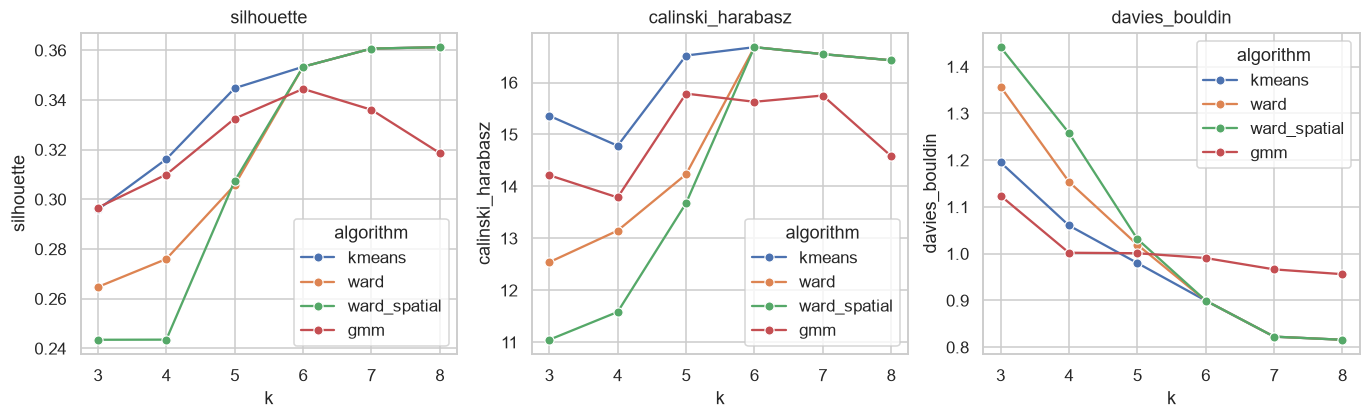

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a_, m in zip(ax, ["silhouette", "calinski_harabasz", "davies_bouldin"]):
    sns.lineplot(data=show, x="k", y=m, hue="algorithm", marker="o", ax=a_)
    a_.set_title(m)
savefig("04_cluster_model_selection"); plt.show()

## 2. The zones

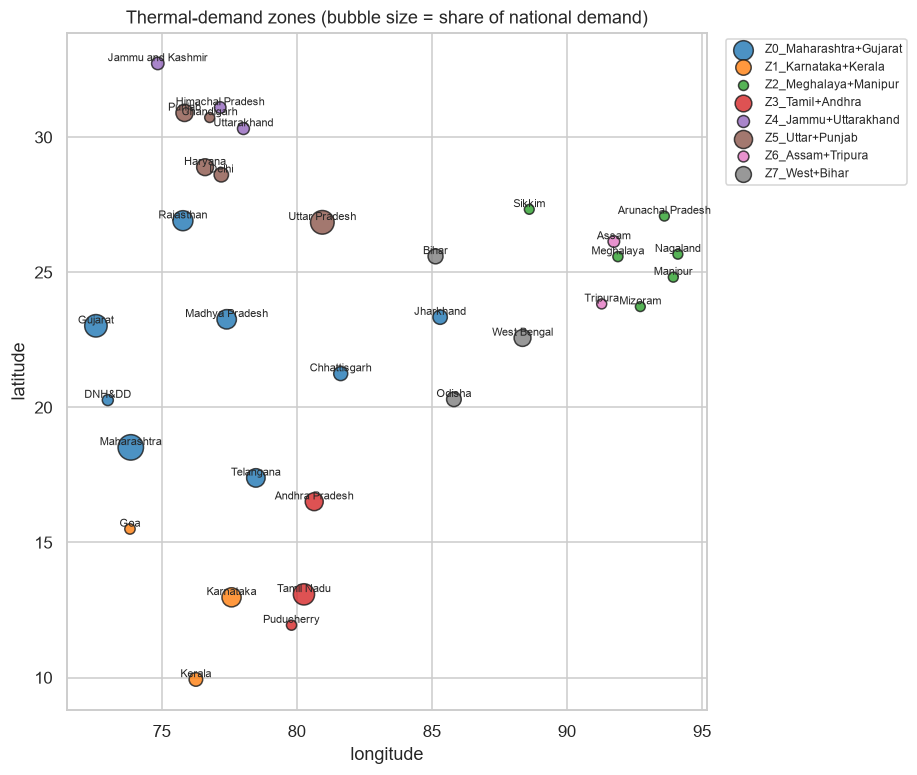

,members
zone,
Z0_Maharashtra+Gujarat,"Chhattisgarh, Gujarat, Jharkhand, Madhya Prade..."
Z1_Karnataka+Kerala,"Goa, Karnataka, Kerala"
Z2_Meghalaya+Manipur,"Arunachal Pradesh, Manipur, Meghalaya, Mizoram..."
Z3_Tamil+Andhra,"Andhra Pradesh, Puducherry, Tamil Nadu"
Z4_Jammu+Uttarakhand,"Himachal Pradesh, Jammu and Kashmir, Uttarakhand"
Z5_Uttar+Punjab,"Chandigarh, Delhi, Haryana, Punjab, Uttar Pradesh"
Z6_Assam+Tripura,"Assam, Tripura"
Z7_West+Bihar,"Bihar, Odisha, West Bengal"


In [6]:
labels = best["labels"]
names = CL.name_zones(sig, labels, w)
zones = sig.assign(zone_id=labels, zone=[names[int(z)] for z in labels])
fig, ax = plt.subplots(figsize=(8, 8))
pal = sns.color_palette("tab10", len(names))
for z, g in zones.groupby("zone_id"):
    ax.scatter(g.lon, g.lat, s=2000 * w.reindex(g.index).fillna(0.001) + 40, color=pal[z], label=names[z], alpha=.8, edgecolor="k")
    for s, r in g.iterrows():
        ax.annotate(s.replace("The Dadra and Nagar Haveli and Daman and Diu", "DNH&DD"), (r.lon, r.lat), fontsize=7, ha="center", va="bottom")
ax.set(xlabel="longitude", ylabel="latitude", title="Thermal-demand zones (bubble size = share of national demand)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1)); ax.set_aspect("equal"); savefig("04_zone_map"); plt.show()
zones.groupby("zone").apply(lambda g: ", ".join(g.index)).to_frame("members")

In [7]:
prof = zones.groupby("zone")[["tmax_premonsoon_AMJ", "rh_mean", "heat_days_per_year", "heat_sensitivity_pct_per_C",
                              "summer_winter_ratio", "monsoon_dip"]].mean()
prof["demand_share"] = w.groupby(zones["zone"]).sum()
prof.round(2)

,tmax_premonsoon_AMJ,rh_mean,heat_days_per_year,heat_sensitivity_pct_per_C,summer_winter_ratio,monsoon_dip,demand_share
zone,,,,,,,
Z0_Maharashtra+Gujarat,37.98,62.43,17.81,0.80,0.93,0.95,0.44
Z1_Karnataka+Kerala,32.81,77.79,16.96,3.22,0.99,0.89,0.08
Z2_Meghalaya+Manipur,30.14,78.99,14.88,-0.34,0.87,1.01,0.01
Z3_Tamil+Andhra,36.20,74.59,17.12,1.98,1.10,0.92,0.13
Z4_Jammu+Uttarakhand,30.47,68.27,16.31,-0.14,0.87,0.99,0.03
Z5_Uttar+Punjab,37.68,64.95,17.22,2.82,1.21,1.20,0.21
Z6_Assam+Tripura,30.23,79.34,14.55,3.50,1.19,1.12,0.01
Z7_West+Bihar,35.91,74.99,16.70,2.78,1.23,1.03,0.09


## 3. Sanity check against the official grid regions
The zones partly agree with the grid regions (ARI ~ 0.4). They are clearly related but not copies, which is the point.
For example, Rajasthan (NR) joins the semi-arid, irrigation-heavy western/central belt, and Bihar/Odisha/West Bengal form a humid eastern zone.

In [8]:
pd.crosstab(zones["zone"], zones["grid_region"])

grid_region,ER,NER,NR,SR,WR
zone,,,,,
Z0_Maharashtra+Gujarat,1,0,1,1,5
Z1_Karnataka+Kerala,0,0,0,2,1
Z2_Meghalaya+Manipur,1,5,0,0,0
Z3_Tamil+Andhra,0,0,0,3,0
Z4_Jammu+Uttarakhand,0,0,3,0,0
Z5_Uttar+Punjab,0,0,5,0,0
Z6_Assam+Tripura,0,2,0,0,0
Z7_West+Bihar,3,0,0,0,0


In [9]:
zones.to_csv(C.PROCESSED_DIR / "state_signatures_and_zones.csv")
show.to_csv(C.METRICS_DIR / "clustering_model_selection.csv", index=False)
print("saved zones for", len(zones), "states")

saved zones for 33 states
